# Fase 5 · Análisis de resultados

**Detección de exoplanetas en Kepler con una red multirrama — iteración 2** (más datos, entrenamiento en GPU)

Curso de Deep Learning · Especialización en Inteligencia Artificial · Universidad Nacional de Colombia

**Autores:** Thomas Monnier Granda, Esteban Felipe Genes Noya, Juan Sebastian Higuita Riascos, Alexandra Arias Mazo y Eliel Segura Perez

> **Pregunta de este cuaderno:** ¿la red multirrama aprende de las curvas, y es mejor que un modelo tabular sobre los mismos datos?

Este cuaderno no entrena nada: lee las evidencias que dejaron los pasos 1 a 5 (`iteracion_2/*.bat`) y las explica. Cada cifra sale de un archivo del repositorio.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import apoyo  # iteracion_2/notebooks/apoyo.py: rutas, lectura de evidencias y figuras

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
apoyo.estilo()
print("Raíz del repositorio:", apoyo.RAIZ.name, "| evidencias en", apoyo.EVIDENCIAS.relative_to(apoyo.RAIZ))

Raíz del repositorio: Proyecto_Final | evidencias en iteracion_2/evidencias


## 1. La comparación que decide

Todos los modelos se evalúan sobre **las mismas señales**, con las mismas particiones. Los modelos
tabulares son *gradient boosting* entrenados con los parámetros del catálogo (sin columnas con fuga):
uno sin el centroide y otro con él. La métrica es el AUC de planeta frente a falso positivo; los
intervalos remuestrean por estrella.

Señales comparadas: 4471 | sin predicción de la fusión: 0


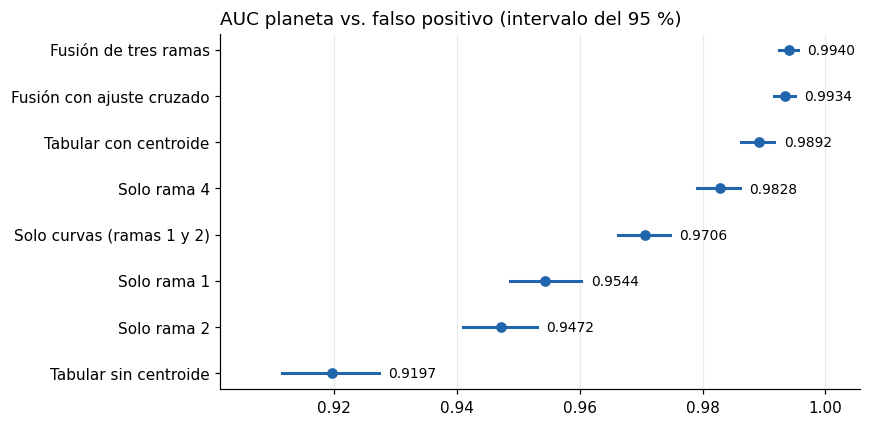

,AUC
Fusión de tres ramas,0.9940 [0.9924; 0.9955]
Fusión con ajuste cruzado,0.9934 [0.9916; 0.9951]
Tabular con centroide,0.9892 [0.9863; 0.9917]
Solo rama 4,0.9828 [0.9791; 0.9861]
Solo curvas (ramas 1 y 2),0.9706 [0.9663; 0.9747]
Solo rama 1,0.9544 [0.9486; 0.9603]
Solo rama 2,0.9472 [0.9410; 0.9531]
Tabular sin centroide,0.9197 [0.9116; 0.9273]


In [2]:
r = apoyo.comparacion()
print("Señales comparadas:", r["n_kois"], "| sin predicción de la fusión:", r["n_kois_sin_prediccion_de_la_fusion"])
orden = ["tabular_sin_centroide", "solo_transitos", "solo_vistas", "solo_curvas", "solo_escalares",
         "tabular_con_centroide", "tres_ramas_ajuste_cruzado", "tres_ramas"]
fig, eje = plt.subplots(figsize=(7.5, 4.2))
apoyo.bosque({k: r["auc"][k] for k in orden[::-1]}, "AUC planeta vs. falso positivo (intervalo del 95 %)", eje=eje)
apoyo.guardar(fig, "05_bosque_auc")
plt.show()
display(pd.DataFrame({apoyo.FUSIONES[k]: {"AUC": apoyo.con_intervalo(r["auc"][k])} for k in orden[::-1]}).T)

## 2. Las diferencias pareadas

Comparar intervalos a ojo engaña. Lo correcto es calcular la **diferencia** en cada remuestreo.

In [3]:
filas = [{"comparación": k.replace("tres_ramas", "fusión").replace("_", " "),
          "diferencia de AUC": apoyo.con_intervalo(v, signo=True), "¿distinguible de cero?": apoyo.distinguible(v)}
         for k, v in r["diferencias"].items()
         if k.startswith(("tres_ramas -", "solo_curvas -"))]
display(pd.DataFrame(filas).set_index("comparación"))
criterio = r["criterio_declarado"]
print("Criterio declarado antes de entrenar:", criterio["regla"])
print("  diferencia:", apoyo.con_intervalo(criterio["diferencia"], signo=True), "→ se cumple:", criterio["se_cumple"])

,diferencia de AUC,¿distinguible de cero?
comparación,,
fusión - tabular sin centroide,+0.0743 [+0.0668; +0.0822],sí
fusión - tabular con centroide,+0.0048 [+0.0025; +0.0073],sí
solo curvas - tabular sin centroide,+0.0510 [+0.0438; +0.0588],sí
solo curvas - tabular con centroide,-0.0185 [-0.0230; -0.0139],sí
fusión - solo escalares (aporte de las curvas a la fusión),+0.0112 [+0.0083; +0.0143],sí
fusión - solo curvas (aporte de los escalares a la fusión),+0.0233 [+0.0199; +0.0269],sí
fusión - fusión ajuste cruzado (efecto del apilado),+0.0005 [-0.0004; +0.0015],no


Criterio declarado antes de entrenar: la fusión supera de forma distinguible al tabular sin centroide
  diferencia: +0.0743 [+0.0668; +0.0822] → se cumple: True


**Cómo leer esta tabla, sin sobrevender:**

- **El criterio declarado se cumple**, pero era fácil: la rama 4 incluye el centroide y ella sola ya
  supera al tabular sin centroide. Cumplirlo no prueba que las curvas aporten.
- **Solo curvas − tabular sin centroide** es la prueba de que la red aprende de la luz: sin ver ningún
  dato del catálogo, las ramas 1 y 2 superan a un modelo tabular de los parámetros del tránsito.
- **Fusión − tabular con centroide** es la comparación exigente. La fusión gana por poco, pero de
  forma distinguible. En la iteración 1 (262 señales) esta comparación había quedado en empate.
- **Las curvas solas no reemplazan al centroide:** quedan por debajo del tabular con centroide. Esa
  información espacial es la que debe aportar la rama de imagen.
- **Aporte de las curvas a la fusión:** la fusión completa supera a la rama de escalares sola. Las
  curvas suman información que los escalares no tienen.

## 3. Dónde acierta y dónde falla

In [4]:
tabla, p = apoyo.predicciones("tres_ramas")
y = tabla["clase"].to_numpy()
confusion = pd.crosstab(pd.Series(y, name="real").map(dict(enumerate(apoyo.CLASES))),
                        pd.Series(p.argmax(1), name="predicho").map(dict(enumerate(apoyo.CLASES))))
display(confusion.reindex(index=apoyo.CLASES, columns=apoyo.CLASES, fill_value=0))
print(f"Aciertos: {(p.argmax(1) == y).mean():.1%} de {len(y)} ejemplos (media de 5 semillas de la cabeza)")

predicho,planeta,falso positivo,sin señal
real,,,
planeta,1976,84,0
falso positivo,73,2332,6
sin señal,0,102,4369


Aciertos: 97.0% de 8942 ejemplos (media de 5 semillas de la cabeza)


In [5]:
m = apoyo.leer_json(apoyo.RESULTADOS / "fusion" / "tres_ramas" / "metricas.json")["semilla_0"]
banderas = {"fp_ss": "eclipse estelar", "fp_co": "desplazamiento de centroide",
            "fp_nt": "no parece tránsito", "fp_ec": "contaminación"}
por_tipo = pd.DataFrame({banderas[k]: {"falsos positivos": v["n"], "detectados": v["aciertos"],
                                        "fracción": v["aciertos"] / v["n"]} for k, v in m["acierto_fp_por_bandera"].items()}).T
por_tipo["fracción"] = por_tipo["fracción"].map("{:.1%}".format)
display(por_tipo.astype({"falsos positivos": int, "detectados": int}))
por_mes = pd.DataFrame(m["auc_por_tercil_mes"]).T.rename(columns={"n": "señales", "estimacion": "AUC"})
display(por_mes)

,falsos positivos,detectados,fracción
eclipse estelar,1404,1380,98.3%
desplazamiento de centroide,1130,1101,97.4%
no parece tránsito,342,317,92.7%
contaminación,731,706,96.6%


,señales,AUC
bajo,1491.0,0.9840
medio,1490.0,0.9949
alto,1490.0,0.9948


Las banderas del catálogo se usan aquí **solo para describir** los errores; nunca fueron entradas.
El tipo más difícil es el que "no parece tránsito", y las señales débiles (tercil bajo de intensidad)
cuestan más que las fuertes, como era de esperar.

Errores tomados al azar con semilla fija, no elegidos a mano:

In [6]:
real = y < 2
errores = np.flatnonzero(real & (p.argmax(1) != y))
rng = np.random.default_rng(apoyo.protocolo()["metricas"]["bootstrap_semilla"])
muestra = np.sort(rng.choice(errores, size=min(8, len(errores)), replace=False))
vista = tabla.loc[muestra, ["id_ejemplo", "periodo_d", "mes"]].copy()
vista["real"] = [apoyo.CLASES[c] for c in y[muestra]]
vista["predicho"] = [apoyo.CLASES[c] for c in p[muestra].argmax(1)]
vista["P(planeta)"] = p[muestra, 0].round(3)
print(f"{len(errores)} errores entre {int(real.sum())} señales reales; se muestran {len(muestra)} al azar")
display(vista.set_index("id_ejemplo"))

163 errores entre 4471 señales reales; se muestran 8 al azar


,periodo_d,mes,real,predicho,P(planeta)
id_ejemplo,,,,,
K02265.01|transito,2.976008,20.244244,falso positivo,planeta,0.778
K00817.02|transito,8.295617,15.260293,planeta,falso positivo,0.204
K06529.01|transito,1.009478,7.566701,falso positivo,sin señal,0.194
K03030.01|transito,7.195526,13.235561,falso positivo,planeta,0.678
K03158.03|transito,6.189440,29.604118,planeta,falso positivo,0.072
K01823.01|transito,4.468457,56.467857,falso positivo,planeta,0.686
K00745.01|transito,16.469838,258.824700,falso positivo,planeta,0.568
K00263.01|transito,20.719272,20.293270,falso positivo,planeta,0.883


## 4. ¿Se puede confiar en la probabilidad?

Un buen orden no basta: si el sistema dice 0,9, unas nueve de cada diez deberían ser planetas.

Error de calibración esperado (ECE): 0.012


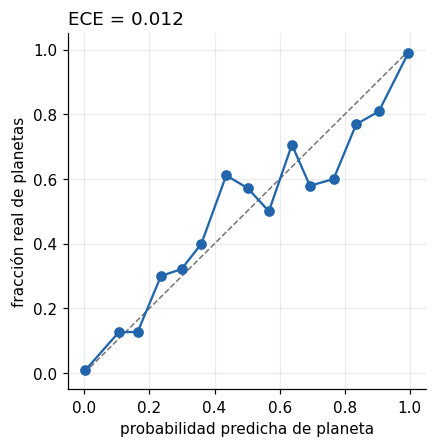

In [7]:
q = p[real, 0] / (p[real, 0] + p[real, 1])   # P(planeta | planeta o falso positivo)
fig, eje = plt.subplots(figsize=(4.2, 4.2))
ece = apoyo.confiabilidad(q, y[real] == 0, apoyo.protocolo()["metricas"]["ece_intervalos"], eje)
apoyo.guardar(fig, "05_confiabilidad")
print(f"Error de calibración esperado (ECE): {ece:.3f}")

## 5. ¿Cambia algo si los modelos se eligen por AUC? (exploratorio)

La misma fusión, con codificadores elegidos por AUC de validación en lugar de NLL.

In [8]:
e = apoyo.comparacion("fusion_exploratoria_auc")
print(e["caracter"])
display(pd.DataFrame({"elegidos por NLL (principal)": {apoyo.FUSIONES[k]: r["auc"][k]["estimacion"] for k in orden if not k.startswith("tabular")},
                      "elegidos por AUC (exploratorio)": {apoyo.FUSIONES[k]: e["auc"][k]["estimacion"] for k in orden if not k.startswith("tabular")}}))

exploratorio: modelos elegidos por AUC de validación, no por NLL


,elegidos por NLL (principal),elegidos por AUC (exploratorio)
Solo rama 2,0.9472,0.9519
Solo rama 1,0.9544,0.9602
Solo curvas (ramas 1 y 2),0.9706,0.9721
Solo rama 4,0.9828,0.9827
Fusión con ajuste cruzado,0.9934,0.9930
Fusión de tres ramas,0.9940,0.9927


Las ramas que leen curvas mejoran un poco eligiendo por AUC, pero **la fusión completa no**. El criterio
declarado (NLL) queda respaldado a nivel de sistema.

## 6. Conclusiones y límites

**Lo que los datos sostienen**

1. Con 17 veces más señales, la fusión de tres ramas supera de forma distinguible al modelo tabular con
   centroide sobre las mismas señales. Con 262 señales no lo lograba.
2. Las ramas que leen las curvas, sin ningún dato del catálogo, superan a un modelo tabular sin centroide:
   la red aprende de la luz.
3. Las curvas suman a la fusión algo que los escalares solos no dan.
4. La búsqueda de hiperparámetros ayuda poco; la mejora grande vino de los datos.

**Lo que no se puede afirmar**

- La ventaja sobre el tabular con centroide es pequeña (milésimas de AUC).
- Los codificadores usan una sola semilla; no se midió su variación.
- `koi_score`, el comparador externo que contiene la decisión del Robovetter, sigue por encima; no es
  una comparación justa (ve lo que aquí está prohibido), pero es el techo de referencia.
- Las señales prerregistradas aún no se evalúan: se hará una sola vez, al final.
- Los aciertos de tres clases incluyen la clase *sin señal*, que la rama 4 reconoce por un atajo (nunca
  tiene centroide; ver cuaderno 1). La conclusión se apoya en el AUC planeta vs. falso positivo, que no lo usa.
- La rama de imagen no participa. Nada aquí habla de habitabilidad ni de atmósferas.
- Las cifras de la iteración 1 y la 2 no son comparables directamente: las muestras son distintas.